# Quantitative Tissue Phenotyping

Author and pipeline lead: Yang Cheng, University of Virginia (UVA), Christopher Deppmann and Melanie Worley laboratories.

Developed with assistance from ChatGPT (OpenAI) in coding, documentation and tutorial preparation.

Quantitative Tissue Phenotyping connects segmentation masks, per-object marker measurements and anatomical regions to characterize tissue phenotypes at single-cell resolution. It can be used with tissue immunofluorescence, fluorescence-based immunohistochemistry and HCR images when the images contain a suitable nuclear marker and aligned marker channels. A Drosophila wing disc with an ectopic structure serves as the worked example.

## Applications and scope

The same image-and-mask workflow can quantify fluorescence from antibody staining or HCR within segmented nuclei or suitable whole-cell masks, then compare marker-positive populations across anatomical regions. The supplied example measures nuclear mean intensity; HCR puncta counting and transcript assignment would require additional analysis. Chromogenic immunohistochemistry would require stain-specific image preprocessing and validation before using the measurement workflow.

The region selection, gating and spatial visualization could potentially be adapted for spatial-omics data with compatible per-cell measurements and registered spatial coordinates. Such an adaptation would require a data importer, appropriate normalization and validation for that assay. The current worked example demonstrates the workflow on wing-disc fluorescence images; it does not demonstrate a spatial-omics analysis.

## Why this pipeline is useful

Tissue immunofluorescence images are often interpreted through qualitative observations of morphology and marker expression. Those observations reveal where a phenotype occurs, but systematic comparisons also require cell counts, marker measurements and a consistent definition of the anatomical region being compared. This pipeline provides a practical way to obtain those measurements while keeping each object linked to its position in the tissue.

For example, it lets users ask: How many cells are GFP-positive in the original pouch, and how many are GFP-positive in the ectopic pouch? What fraction of the cells in each region passes the same GFP threshold? How does the distribution of GFP intensity differ between those regions?

## What the pipeline measures

1. Segment individual nuclei using a nuclear marker such as DAPI. A nuclear channel is sufficient input for the nuclear-only workflow; additional marker channels can then be quantified within those masks.
2. Measure the mean raw fluorescence intensity of every marker channel within each segmented nucleus, producing a table of marker abundance estimates for individual objects. With suitable whole-cell masks, the same measurement principle applies to cells. Fluorescence intensity is a relative readout of marker abundance within the measured compartment, rather than an absolute molecule count.
3. Define anatomical regions by freehand drawing, count the segmented objects within each region, and retain their individual marker measurements. Marker thresholds identify positive populations and support regional counts and percentages, such as GFP-positive nuclei in the original versus ectopic pouch.

The intended output is a set of quantitative phenotype descriptions: where marker-enriched cells are located, how many occur in each region, and how strongly individual nuclei or cells express the measured markers. Segmentation and gate choices should be checked against the images before interpreting these measurements.

## Nuclear and whole-cell segmentation

In the supplied dataset, all four channels label nuclear signals: C1 GFP, C2 unidentified marker, C3 DAPI and C4 RFP. We therefore used DAPI alone as the segmentation input and measured all four raw channels within the resulting nuclear masks. In this example, a counted object is a segmented nucleus; no whole-cell boundary is inferred from these nuclear channels.

With a nuclear marker plus a suitable membrane or cytoplasmic marker, an appropriate DeepCell application such as Mesmer can produce nuclear and whole-cell segmentations, allowing marker measurements in each compartment. The quality of the additional boundary signal and performance on the tissue must be checked. This capability is described in the [DeepCell Mesmer documentation](https://deepcell.readthedocs.io/en/master/app-gallery/mesmer.html) and the [Mesmer methods paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC9010346/). Whole-cell segmentation code is outside this nuclear-only worked example.

The recorded analysis applied a pretrained DeepCell nuclear model and tuned preprocessing, input scale and filtering. It did not train a new model on annotated wing-disc images.

## Start with the original image stack

The source image, ectopic disc 2 (pdm2), is a four-channel Z-stack with 52 slices per channel. The embedded acquisition metadata records a 10× objective, specifically Plan-Apochromat 10x/0.45 M27, and a 2 µm interval between adjacent Z-slices. Each slice is 2189 × 1152 pixels, with an XY pixel size of approximately 0.5546 µm.

The goal of plane selection is to sample representative tissue depths without collapsing the entire disc into one projection. We first chose a central tissue view that includes the intact wing disc and the ectopic structure, then selected equally spaced views above and below it. Here, “middle” refers to that anatomically selected reference view, rather than necessarily the numerical midpoint of the acquired stack.

## Prepare three representative projections in FIJI

1. Open the original four-channel stack in FIJI and inspect the Z-slices. Identify a central reference view that captures the intact wing disc and ectopic structure while allowing individual nuclei to be resolved.
2. Make a maximum-intensity projection of the two adjacent slices chosen for that reference view. For this example, the middle projection uses Z33–Z34, with slice numbers counted from 1.
3. Select matching two-slice ranges at equal distances above and below the middle pair. This example uses Z28–Z29 for the top projection and Z38–Z39 for the bottom projection. Corresponding slices in neighboring pairs differ by five Z-steps, or 10 µm; the projection-pair midpoints are therefore also 10 µm apart.
4. For each range, use Image > Stacks > Z Project in FIJI, set the start and stop slices, and choose Max Intensity. Apply the same slice range separately across all four channels, retaining a four-channel image rather than an RGB composite. Save each result as a separate TIFF with C = 4 and Z = 1, preserving the original bit depth and XY calibration.

Each projection combines two adjacent slices sampled 2 µm apart. The result is three representative 2D views of this disc, not a 3D reconstruction. Use the same number of adjacent slices for all three projections and record their exact slice ranges. Select suitable reference depths for each new specimen rather than copying these numerical ranges automatically.

![Three representative DAPI projections from the supplied example](assets/representative_planes.png)

The example above shows the top, middle and bottom DAPI projections from slide 2 of the supplied presentation. The three views use Z28–Z29, Z33–Z34 and Z38–Z39, respectively. Each saved image also retains GFP, C2 and RFP as separate channels.

## Preserve raw intensities for quantification

Brightness and contrast changes are unnecessary for measurement. FIJI display adjustments may help visual inspection, provided they do not alter the pixel values used for quantification. Do not apply contrast rescaling to the analysis images, convert them to 8-bit or RGB, or replace their marker channels with enhanced images.

DAPI core enhancement is a separate processing step used to prepare the segmentation input. Once masks are available, all marker means are calculated from the unenhanced projected channels. Each projected pixel is the maximum of its two source slices in that channel, so “raw” here means the unmodified intensity of the saved maximum projection. Different channels can obtain their maxima from different source slices.

The three representative projections were segmented independently using DAPI, then used for marker measurement and regional phenotyping. The example contains 6,847 top-plane masks, 7,253 middle-plane masks and 7,380 bottom-plane masks. There is no cross-plane matching: the total of 21,480 plane-specific masks should not be interpreted as 21,480 unique cells throughout the disc.

## Follow the worked example

The next section documents segmentation in the original UVA DeepCell environment. Users with existing masks can skip to Installation and example files. The locally runnable measurement tutorial starts with the saved segmentation labels. It includes a small real four-channel TIFF crop with 416 complete nuclear masks and the full measurement table for all three planes. Follow the code blocks to measure raw intensities, select nuclei with marker gates, inspect their locations, define regions and export regional summaries.

Download the complete tutorial bundle to keep the code, notebook and example data together. The original DeepCell segmentation ran on HPC; its saved labels let you follow the measurement and phenotyping steps without an HPC account. Images and recorded results are displayed on this page, while the analysis itself runs in Python or the matching notebook.

## Segment nuclei in the UVA DeepCell environment

This stage starts with the three four-channel projections prepared in FIJI. It produces nuclear label TIFFs on the original pixel grid, ready for raw-channel measurement. If you already have these masks, continue to Installation and example files below.

The original enhancement and segmentation notebooks have been recovered from UVA HPC. The observed environment was Python 3.10.20, DeepCell 0.12.10, TensorFlow 2.8.4 and an NVIDIA RTX 3090. Use the existing compatible UVA DeepCell kernel for this stage. A local CPU environment used for the downstream tutorial does not establish that GPU inference can run locally.

Download the [segmentation notebook](Segmentation_Tutorial.ipynb), the [reusable segmentation module](code/nuclear_segmentation.py) and the [observed environment record](segmentation_environment.txt), or obtain them together in the complete bundle. The notebook walks through one representative plane, displays QC before saving, then provides an optional batch step. Its inference cells have no execution outputs because they have not been rerun locally. Use your own DeepCell model access in your own environment. No API key or model weights are included.

### Your original scripts and environment settings

The original analysis used the Jupyter kernel DeepCell ICC GPU (`deepcell_icc_gpu`). Select that kernel in your existing UVA HPC Jupyter session. The recorded versions are Python 3.10.20, DeepCell 0.12.10 and TensorFlow 2.8.4, with an NVIDIA RTX 3090 GPU. The [environment settings file](segmentation_environment.txt) and [machine-readable environment record](data/hpc_environment.json) preserve these details.

Your original scripts are included as unmodified downloads:

1. [Core_Enhancement_Wing_Disc.py](source_workflows/Core_Enhancement_Wing_Disc.py): raw DAPI inspection, core-enhancement trials and export of the three enhanced DAPI images.
2. [Wing_Disc_Nuclear_Segmentation_Clean.py](source_workflows/Wing_Disc_Nuclear_Segmentation_Clean.py): DeepCell diagnostics, input-scale trials, nuclear prediction, tissue filtering, boundary review and final exports.

The corresponding [enhancement source notebook](source_workflows/Core_Enhancement_Wing_Disc_source.ipynb) and [segmentation source notebook](source_workflows/Wing_Disc_Nuclear_Segmentation_Clean_source.ipynb) retain the original cell sources and kernel metadata, with historical outputs removed for distribution. The [script hashes](data/original_script_manifest.json) identify the exact recovered Python exports.

These original files document the development of the analysis. Their earlier trial cells also run if the entire Python export is executed. For routine incorporation, follow the accepted steps in `Segmentation_Tutorial.ipynb` or import `code/nuclear_segmentation.py`. See the [source workflow notes](source_workflows/README.txt) for the distinction.

The original scripts expect a working directory containing these files:

```text
project_folder/
    top_Z28-Z29_4channels.tif
    middle_Z33-Z34_4channels.tif
    bottom_Z38-Z39_4channels.tif
    DAPI_Core_Enhanced/
        enhancement_settings.json
        top_DAPI_core_enhanced.tif
        middle_DAPI_core_enhanced.tif
        bottom_DAPI_core_enhanced.tif
```

Run enhancement before segmentation when using those original files. They contain example-specific paths, channels, dimensions and crop coordinates; adapt those values to new data. Their final segmentation export writes a new timestamped output folder.

### Record the active HPC environment

A complete Conda environment export, original activation command, CUDA/cuDNN versions and job-allocation settings were not recovered. The observed-version record should therefore accompany the tutorial as provenance, rather than serve as a tested installation recipe.

To capture more detail, run this cell inside the DeepCell ICC GPU notebook kernel, with the tutorial folder as the working directory. The [environment capture helper](code/capture_deepcell_environment.py) records installed package versions and TensorFlow GPU visibility. It does not run segmentation, download a model or read authentication variables.

```python
import sys
import json
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / 'code'))
from capture_deepcell_environment import capture_environment

with Path('deepcell_environment_capture.json').open('x') as handle:
    json.dump(capture_environment(), handle, indent=2, default=str)
```

Keep that JSON with the run settings. The tutorial uses your own existing DeepCell model access in the HPC environment; keys are not stored in the distributed files.

### Prepare the segmentation input

The accepted enhancement uses Gaussian smoothing at sigma 0.5 pixels, subtraction of a broad Gaussian background at sigma 12 pixels, and a nonnegative scale-normalized negative Laplacian of Gaussian response at sigma 1.8 pixels. The module creates a separate floating-point image; the original fluorescence channels remain the measurement source.

```python
from nuclear_segmentation import enhance_dapi

# raw is your four-channel CYX maximum projection.
dapi = raw[2]  # C3 DAPI, zero-based channel index
core = enhance_dapi(dapi)
```

The pretrained application was loaded with `NuclearSegmentation.from_version('1.1')`. The accepted input was enlarged threefold with linear interpolation and passed with `image_mpp=app.model_mpp`, where the recorded model pixel size was 0.65 µm. Predicted labels were resized back with nearest-neighbor interpolation. This was an empirical adjustment of apparent nuclear size, not a change in the microscope calibration. Physical measurements still use 0.5546 µm per original pixel. New images require their own segmentation review and parameter selection.

```python
from nuclear_segmentation import load_nuclear_model, predict_nuclei

# Run these lines in the compatible DeepCell environment.
app = load_nuclear_model()
initial_labels = predict_nuclei(core, app)
```

### Filter background detections and inspect the result

A tissue mask comes from raw DAPI smoothed at sigma 12 pixels and thresholded at 0.5× Otsu, followed by closing with a 32 pixel disk, removal of components smaller than 5,000 pixels and hole filling. A nucleus must have at least 50% overlap with tissue.

The boundary check examines nuclei intersecting a 10 pixel band around the tissue edge. It compares median nuclear DAPI with median local background in a 2–5 pixel ring, excluding other detected nuclei. With at least 10 ring pixels, a ratio below 1.2 flags the nucleus for exclusion. Unevaluable nuclei remain. The original flags were visually reviewed before acceptance. The helper applies the recorded rule and returns per-label QC records; review the exclusions on every new specimen before phenotyping.

```python
from nuclear_segmentation import filter_nuclei

labels, tissue, summary, boundary_qc = filter_nuclei(dapi, initial_labels)
print(summary)
```

![Saved middle-plane preview from the original UVA HPC segmentation run](assets/middle_hpc_segmentation.png)

This is the saved preview from the original HPC run, not a new local inference result. Additional original previews are available for the [top plane](assets/top_hpc_segmentation.png) and [bottom plane](assets/bottom_hpc_segmentation.png). The recovered run record contains these counts:

1. Top: 31,580 initial detections → 7,050 after tissue overlap → 203 boundary exclusions → 6,847 retained nuclei.
2. Middle: 32,347 initial detections → 7,445 after tissue overlap → 192 boundary exclusions → 7,253 retained nuclei. This plane reused its previously reviewed result.
3. Bottom: 32,161 initial detections → 7,546 after tissue overlap → 166 boundary exclusions → 7,380 retained nuclei.

See the [original settings and counts](data/segmentation_settings.json) and [enhancement settings](data/enhancement_settings.json). These counts document the example; they are not an accuracy estimate against ground-truth annotations.

### Incorporate segmentation into your own pipeline

For a plane with reviewed settings, the convenience function creates a new output folder and saves enhanced DAPI, unfiltered predictions, final nuclear labels, the tissue mask, boundary QC records and settings. Inspect these outputs before downstream analysis. The segmentation notebook shows how to save the already computed representative-plane arrays without repeating inference.

```python
from nuclear_segmentation import save_segmentation

# Requires your own full-plane DAPI and a loaded DeepCell application.
labels, run_record = save_segmentation(
    output_dir='results/new_run/middle',
    plane='middle', raw_dapi=dapi, app=app,
)
```

Keep the final YX labels paired with the unenhanced CYX projection. The next part of this tutorial measures all raw channels within those labels. Keep plane names in the exported records because label IDs are unique only within a plane.

### What has been verified locally

CPU validation reproduced the archived middle-plane enhanced DAPI pixel for pixel and reproduced all three archived tissue masks pixel for pixel. The recalculated middle Otsu threshold differed by approximately 0.00049 intensity units in the newer local libraries, with no change to the tissue mask. Retained mask counts match the recovered record, and all archived boundary exclusions are absent from the saved final masks.

DeepCell inference and the complete filtering chain starting from unfiltered GPU predictions have not been rerun locally. The [verification report](data/segmentation_recovery_validation.json) records the actual checks and local library versions. The executable cells in the main notebook below cover measurement and phenotyping from saved masks.

## Use the interactive interface

[Open the Quantitative Tissue Phenotyping explorer](interface/index.html) to use the working interface with the wing-disc example. It is also included in the complete downloadable tutorial bundle. Extract the bundle and open `interface/index.html` in a desktop browser such as Chrome, keeping `plotly.min.js` in the same folder. The example interface runs locally and does not require an HPC account, Python installation or DeepCell API key.

The interface contains the example raw image pixels, retained nuclear outlines and per-nucleus measurements. It supports marker gating, raw/arcsinh displays, spatial inspection, freehand anatomical regions and regional counts. Changing display contrast does not change measured intensities. It uses the saved masks; it does not perform new segmentation in the browser.

1. Select the top, middle or bottom plane, or All Planes, and choose the three marker axes.
2. Set marker thresholds and inspect the selected population in the scatterplots and paired image views. Enable gate coloring to see passing and failing nuclei on the tissue.
3. Choose Freehand draw, trace the original or ectopic pouch on an image, enter a region name and select Save region. The region table shows total masks, passing masks and their percentage for the current gate.
4. Export thresholds JSON, regions JSON and region counts CSV. Browser storage is convenient, but exported files preserve settings when moving computers or folders.
5. Use the exported JSON files in the Python measurement and phenotyping tutorial below to reproduce the gate and regional summaries.

This distributed explorer is preloaded with the wing-disc example. It does not currently offer a general image-upload workflow. Users can reuse the Python segmentation, measurement and counting modules with their own images now; showing a new dataset in this interface currently requires adapting the asset builder and rebuilding the page. A general data-import interface remains a development step.

The interface embeds full-resolution images, so its HTML is large and may take time to open. The downloadable bundle includes those image pixels for the worked example, as well as its measurements. It is a local, shareable demo; this tutorial has not been published online.

## Run order and download instructions

The download includes a [step-by-step start guide](START_HERE.html), also supplied as `README.md` and `START_HERE.txt`. It explains which script to run first, the required inputs and generated outputs at every stage, expected results for the example, and the separate route for your own images. Start there after extracting the bundle. The browser example and local measurement example do not require a new DeepCell run.

## Installation and example files

Use Python 3.10 or newer. Extract the bundle, open a terminal in its folder, and install the measurement and plotting libraries. JupyterLab is needed only if you want to run the notebook.

```bash
python -m venv .venv
source .venv/bin/activate
python -m pip install numpy tifffile matplotlib jupyterlab
python -m jupyterlab
```

On Windows, activate the environment with `.venv\Scripts\activate`. Open `Guided_Tutorial.ipynb` in JupyterLab and run the cells in order. The code also works in a Python script. Keep the `data` and `code` folders beside the notebook.

The small TIFF has CYX axes: channel, row, column. Its label TIFF has YX axes, with zero for background and a positive integer for each nucleus. Channel assignments are specific to this example and must be checked on new data.

In [1]:
from pathlib import Path
import csv
import json
import sys

# Find this tutorial whether opened from its own folder or the project root.
candidates = [Path.cwd(), *Path.cwd().parents]
candidates += [p / 'Writeup/tutorial' for p in list(candidates)]
TUTORIAL = next(p for p in candidates
                if (p / 'data/crop_manifest.json').exists())
sys.path.insert(0, str(TUTORIAL / 'code'))
RESULTS = TUTORIAL / 'results'
RESULTS.mkdir(exist_ok=True)

import numpy as np
import tifffile
import matplotlib.pyplot as plt
from measure_nuclei import measure_nuclei
from phenotype_analysis import (
    read_measurements, gate_nuclei, count_regions, write_csv,
)
from tutorial_plots import (
    plot_mask_qc, plot_marker_gate,
    plot_spatial_gate, plot_region_summary,
)

channel_names = ['C1 GFP', 'C2 unknown', 'C3 DAPI', 'C4 RFP']
pixel_size_um = 0.5546006944444444
print('Example channels:', ', '.join(channel_names))

Example channels: C1 GFP, C2 unknown, C3 DAPI, C4 RFP


## Inspect images and nuclear labels

We first load a real middle-plane crop. Both inputs use the original pixel grid, so label pixels select the corresponding raw pixels directly. The crop is 220 columns by 180 rows and contains four channels.

The example retains only nuclei whose entire original mask fits inside this crop. Partial masks were removed to avoid teaching measurement on truncated nuclei. Pixel intensities remain unchanged. The saved label IDs come from the original full-plane segmentation.

Raw: (4, 180, 220) uint16
Labels: (180, 220) uint32
Complete nuclei: 416


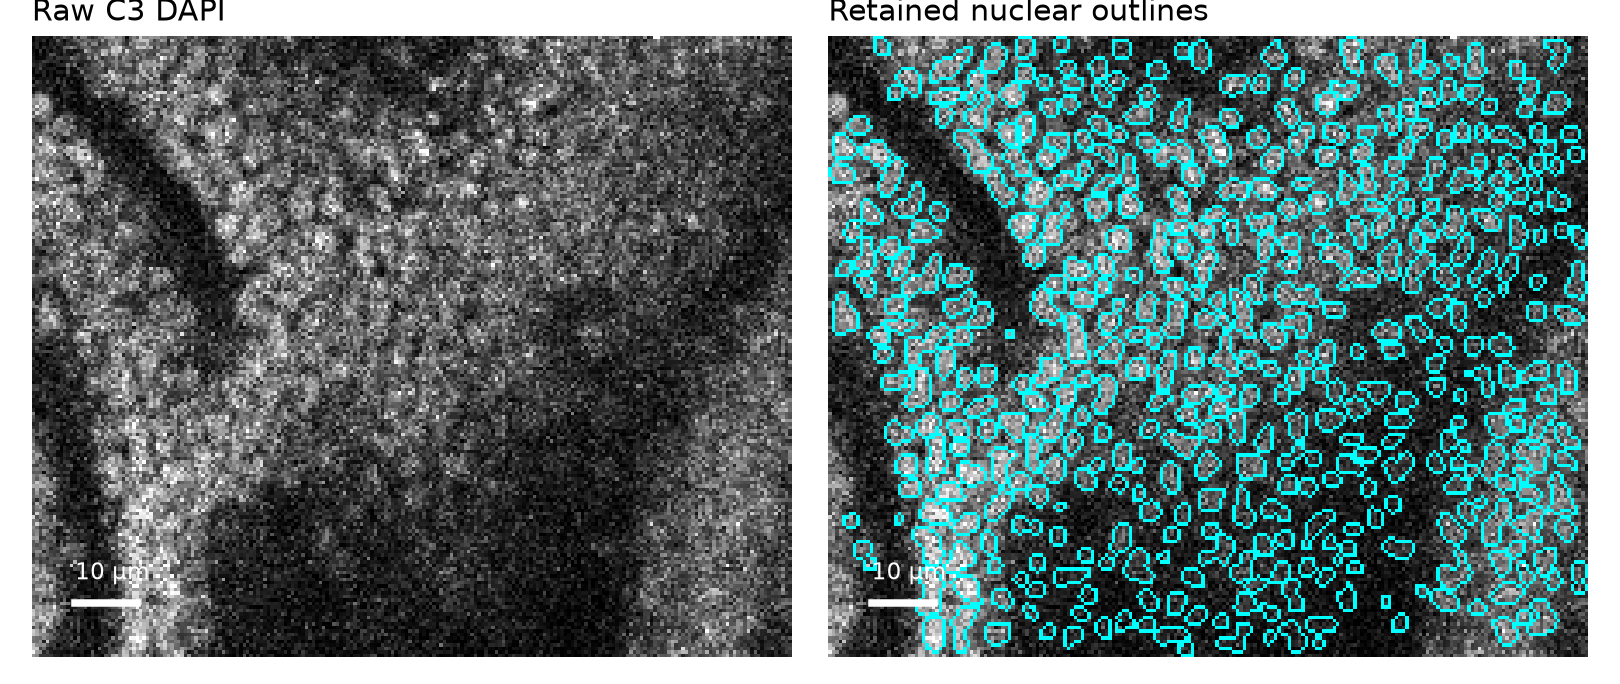

In [2]:
raw = tifffile.imread(TUTORIAL / 'data/middle_crop_raw.tif')
labels = tifffile.imread(TUTORIAL / 'data/middle_crop_labels.tif')
assert raw.shape[1:] == labels.shape
assert raw.shape[0] == len(channel_names)

print('Raw:', raw.shape, raw.dtype)
print('Labels:', labels.shape, labels.dtype)
print('Complete nuclei:', len(np.unique(labels[labels > 0])))

fig = plot_mask_qc(raw[2], labels, pixel_size_um)
fig.savefig(RESULTS / 'mask_qc.png', dpi=180)
plt.show()

The two panels share the same contrast limits. Cyan outlines show the retained labels, and the scale bars are 10 µm. Inspect weak signals, crowded nuclei, splits and merges before accepting measurements. A plausible image does not establish segmentation accuracy.

## Measure raw channel intensities

For each positive label, calculate area, centroid and the arithmetic mean of each original channel. We quantify raw fluorescence rather than the enhanced DAPI used during segmentation. The function keeps the original label IDs.

Centroids use zero-based crop pixels. Nuclear means and areas for these complete masks match their corresponding full-plane measurements; centroid coordinates differ by the crop offset.

In [3]:
crop_rows = measure_nuclei(
    raw, labels, channel_names, pixel_size_um=pixel_size_um,
)
crop_rows = [dict(plane='middle_crop', **row) for row in crop_rows]
write_csv(RESULTS / 'crop_measurements.csv', crop_rows, list(crop_rows[0]))

print(f'Measured {len(crop_rows):,} complete nuclear masks')
print('mask_id  area_px  GFP_mean  DAPI_mean')
for row in crop_rows[:5]:
    print(f"{row['mask_id']:7d}  {row['area_px']:7d}  "
          f"{row['C1 GFP_mean']:8.1f}  {row['C3 DAPI_mean']:9.1f}")

Measured 416 complete nuclear masks
mask_id  area_px  GFP_mean  DAPI_mean
  17415       21   13477.5    16396.5
  17420       26   17773.3    22174.3
  17435       37   17122.8    23295.5
  17436       63   20739.5    30223.0
  17437       51   17869.2    19678.8


For your own images, replace the TIFF paths and channel names, and supply your measured XY calibration. A 2D label mask must align with a CYX raw image. For anisotropic XY pixels, adapt the physical area conversion to use separate x and y spacings.

## Load the full example dataset

We now load the saved measurements for all three planes. This lets the Python example reproduce the full marker-selection analysis without loading full-plane TIFFs. The browser interface separately includes embedded full-resolution image pixels. Every row represents one retained nuclear mask. Use plane plus mask ID as the joint identifier.

Top, middle and bottom are independent 2D projections. Their combined count is a number of plane-specific masks, not a count of unique nuclei throughout the original 3D disc.

In [4]:
rows = read_measurements(TUTORIAL / 'data/nuclear_channel_means.csv')
for plane in ['top', 'middle', 'bottom']:
    print(f"{plane:6s} {sum(r['plane'] == plane for r in rows):6,d} masks")
print(f"total  {len(rows):6,d} masks")

# Verify complete crop measurements against the full middle-plane table.
full_by_id = {r['mask_id']: r for r in rows if r['plane'] == 'middle'}
for row in crop_rows:
    full = full_by_id[row['mask_id']]
    assert row['area_px'] == full['area_px']
    for name in channel_names:
        assert np.isclose(row[name + '_mean'], full[name + '_mean'])
print('All complete crop areas and means match the full-plane table.')

top     6,847 masks
middle  7,253 masks
bottom  7,380 masks
total  21,480 masks
All complete crop areas and means match the full-plane table.


## Select nuclei using marker gates

We select nuclei using GFP, RFP and C2. Every selected channel must meet or exceed its cutoff. The example uses explicitly chosen demonstration cutoffs in raw intensity units. These values illustrate the code and do not establish marker specificity or biological positivity.

Thresholds are stored by plane and channel, allowing different cutoffs when justified. Changing a display to arcsinh should not change these raw cutoffs.

Middle-plane raw cutoffs:
  C1 GFP: 10,000
  C4 RFP: 10,000
  C2 unknown: 5,000
Selected: 5,222 / 21,480 (24.3%)


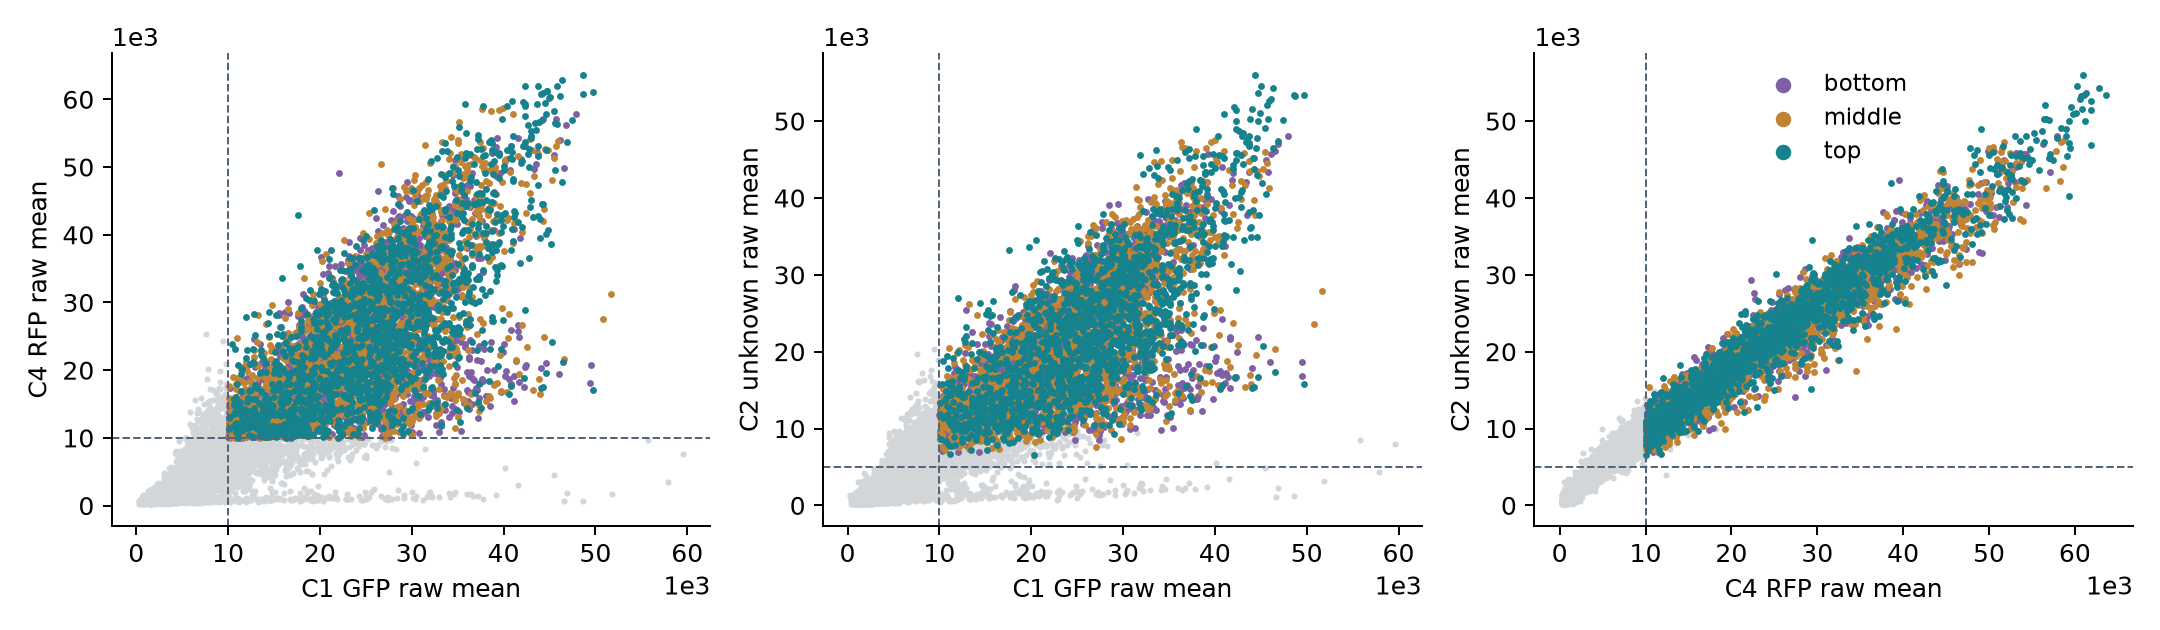

In [5]:
settings = json.loads((TUTORIAL / 'data/demo_thresholds.json').read_text())
channels = settings['selectedMarkers']
cutoffs = settings['thresholdsRaw']
passing = gate_nuclei(rows, channels, cutoffs)
selected = [row for row, keep in zip(rows, passing) if keep]

print('Middle-plane raw cutoffs:')
for channel in channels:
    print(f"  {channel}: {cutoffs['middle'][channel]:,}")
print(f"Selected: {len(selected):,} / {len(rows):,} "
      f"({100 * len(selected) / len(rows):.1f}%)")

fig = plot_marker_gate(rows, passing, channels, cutoffs)
fig.savefig(RESULTS / 'marker_gate.png', dpi=180)
plt.show()

Colored points pass all three criteria, even though each panel displays only two channels. Gray points show the full retained population underneath. Dashed lines mark the raw cutoffs for the plotted channels. Colors identify planes.

To reuse an explorer selection, replace `demo_thresholds.json` with its exported threshold JSON. The code reads `selectedMarkers` and `thresholdsRaw`, independent of the browser display scale.

## Inspect selected nuclei in space

A marker gate should also be checked against the tissue. We map the passing nuclei back to their centroids in the middle plane. This view uses original image pixels, so y increases downward.

This plot is calculated from the same `passing` flags as the marker plots. It does not redefine the selected population.

Middle-plane passing masks: 1,740


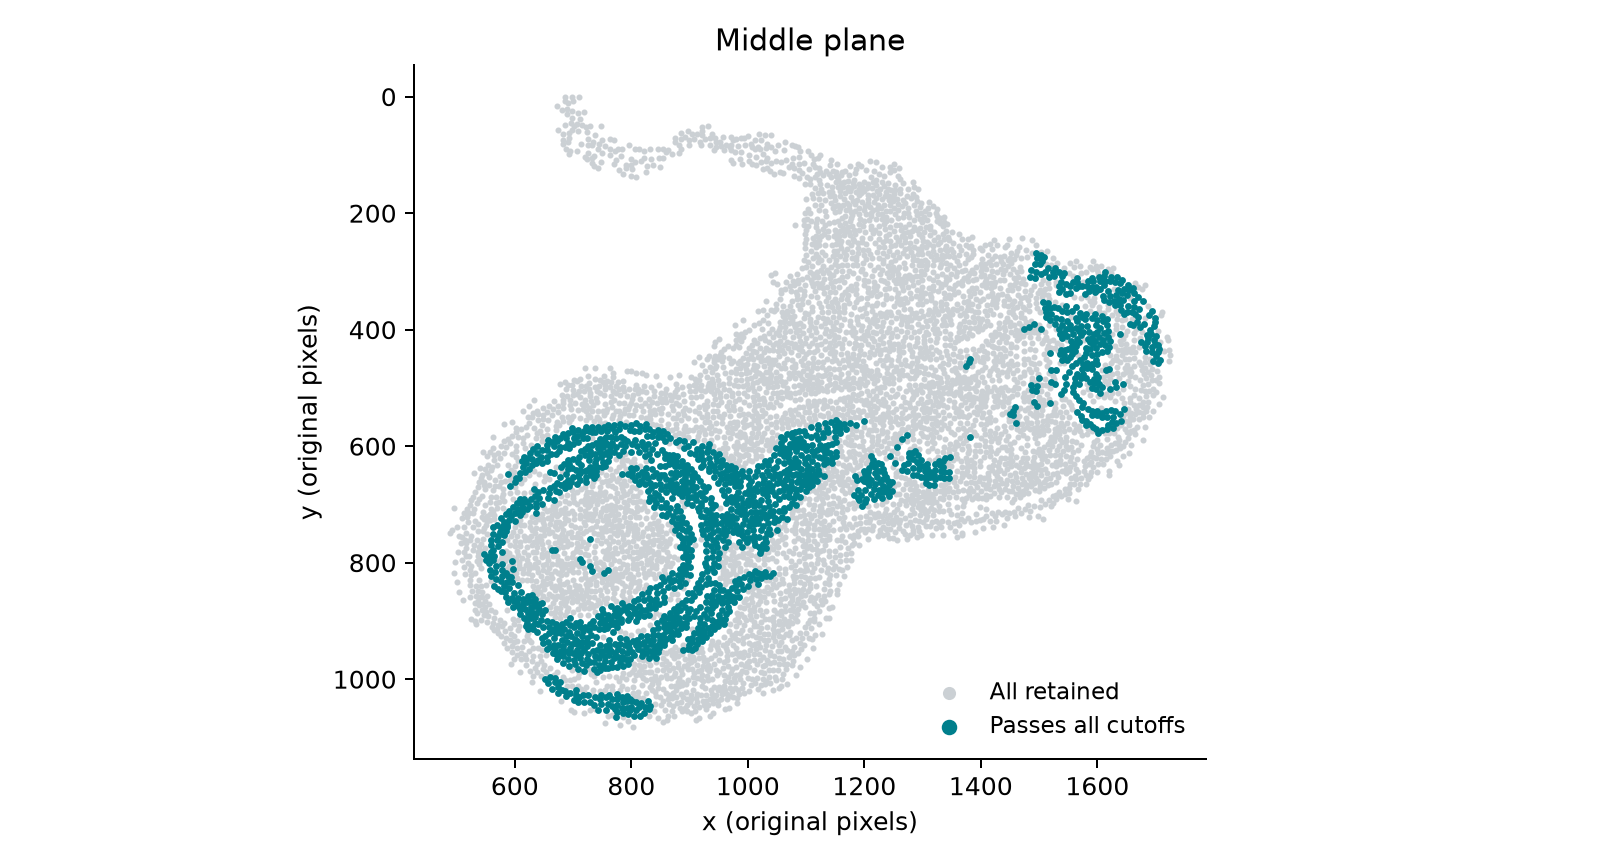

In [6]:
fig = plot_spatial_gate(rows, passing, plane='middle')
fig.savefig(RESULTS / 'spatial_gate.png', dpi=180)
plt.show()

middle_selected = sum(keep and row['plane'] == 'middle'
                      for row, keep in zip(rows, passing))
print(f'Middle-plane passing masks: {middle_selected:,}')

## Draw and export freehand regions

In the phenotype explorer, select a plane and image channel, choose Freehand draw, trace a region, then name and save it. Select Inspect / pan when you want to move around the image. Regions appear on both paired views.

![Saved freehand regions from the supplied presentation](assets/freehand_regions.png)

The image above shows the existing Original pouch and Ectopic pouch boundaries from slide 7 of the supplied presentation. It illustrates the drawing workflow. Its historical gate differs from this runnable demonstration.

Export regions JSON to preserve the exact polygon points. Export thresholds to preserve the gate; the current threshold export also includes saved regions. A mask belongs to a region when its centroid is inside or on the boundary. Overlapping regions count shared nuclei independently.

For a reproducible example without the original freehand exports, we supply two rectangles with explicit coordinates. They are labeled Demo left rectangle and Demo right rectangle and do not claim anatomical boundaries.

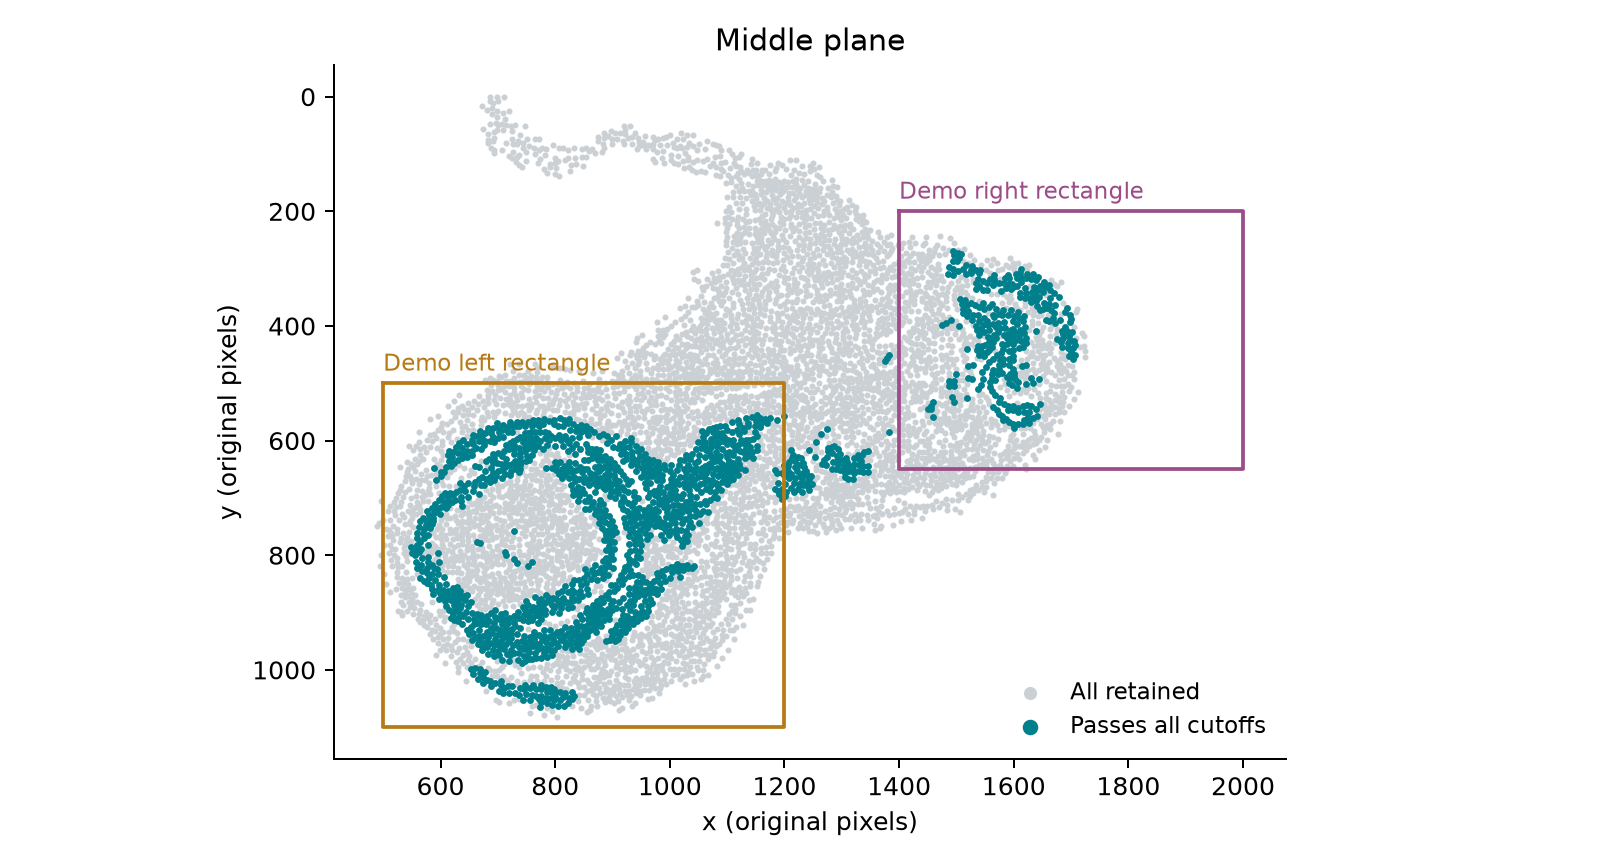

In [7]:
region_export = json.loads((TUTORIAL / 'data/demo_regions.json').read_text())
assert region_export['dataset'] == settings['dataset']
regions = region_export['regions']

fig = plot_spatial_gate(rows, passing, plane='middle', regions=regions)
fig.savefig(RESULTS / 'demo_regions.png', dpi=180)
plt.show()

For your own freehand analysis, substitute the JSON exported from the explorer. Keep centroid and polygon coordinates in the same original pixel system. A resized screenshot cannot replace the saved coordinate list.

## Quantify each region

For each region, the denominator is all retained masks inside it and the numerator is the subset passing the active gate. We report the count and percentage together so the denominator remains visible. An empty region has no defined percentage.

Region                    Total   Passing   Percent
Demo left rectangle       3,693   1,334    36.1%
Demo right rectangle      1,143     312    27.3%


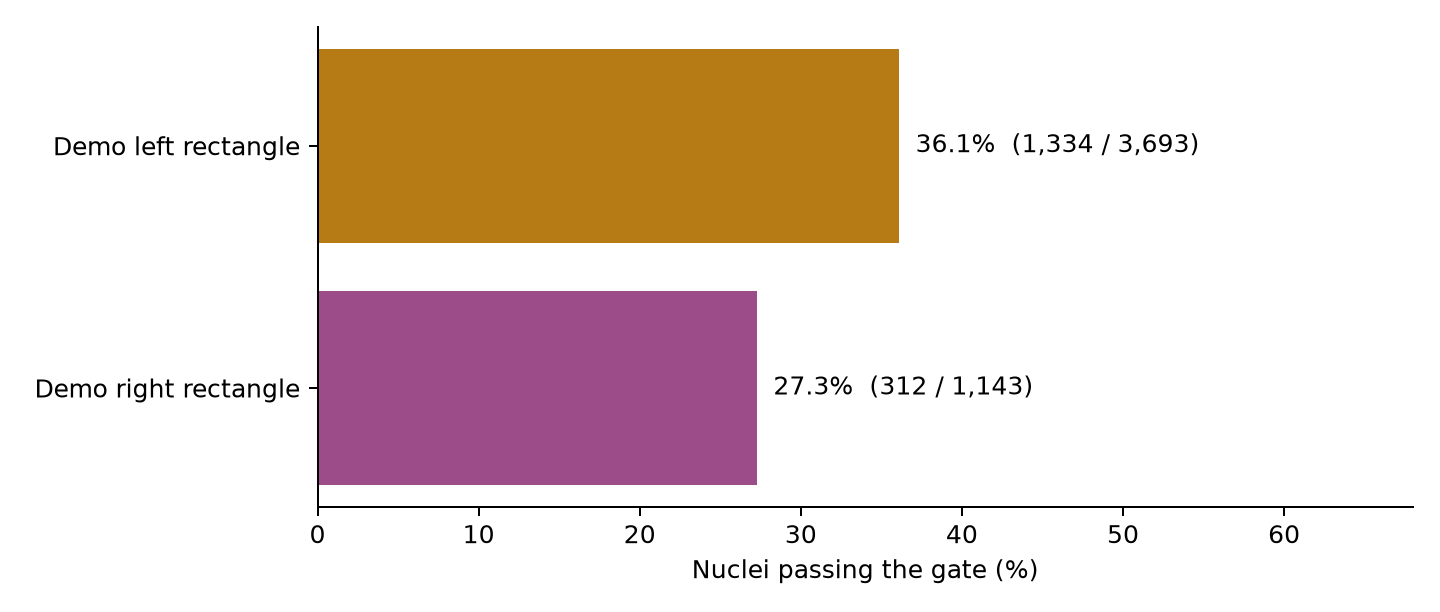

In [8]:
summary = count_regions(rows, passing, regions)
print('Region                    Total   Passing   Percent')
for region in summary:
    print(f"{region['region']:25s} {region['total_masks']:5,d}   "
          f"{region['above_threshold_masks']:5,d}    "
          f"{region['above_threshold_percent']:.1f}%")

fig = plot_region_summary(summary)
fig.savefig(RESULTS / 'region_summary.png', dpi=180)
plt.show()

These plotted counts are freshly calculated from the demonstration rectangles and cutoffs. They can be reproduced by running this notebook.

The supplied presentation also contains the historical anatomical-region table below. Original pouch had 944 passing masks among 2,691 total, while Ectopic pouch had 128 among 1,408. Those screenshot results require their original region geometry and threshold export to reproduce and should not be confused with the demonstration above.

![Historical anatomical-region counts from the supplied presentation](assets/historical_counts.png)

Regional percentages describe the image and selected thresholds. Compare independent biological samples and apply a stated selection rule before interpreting a biological difference.

## Export results for another pipeline

Save all nuclear measurements with their gate flag, the selected nuclei, and the region summary. Retain the raw thresholds and polygon coordinates alongside the tables so the analysis can be repeated.

In [9]:
write_csv(RESULTS / 'gated_nuclei.csv',
          [dict(row, passes_gate=keep) for row, keep in zip(rows, passing)],
          list(rows[0]) + ['passes_gate'])
write_csv(RESULTS / 'selected_nuclei.csv', selected, list(rows[0]))
write_csv(RESULTS / 'region_counts.csv', summary, list(summary[0]))

analysis_settings = dict(
    selected_channels=channels,
    thresholds_raw=cutoffs,
    regions=regions,
    total_masks=len(rows),
    passing_masks=len(selected),
)
(RESULTS / 'analysis_settings.json').write_text(
    json.dumps(analysis_settings, indent=2) + '\n'
)
print('Saved gated_nuclei.csv, selected_nuclei.csv, region_counts.csv')
print('Saved analysis_settings.json')

Saved gated_nuclei.csv, selected_nuclei.csv, region_counts.csv
Saved analysis_settings.json


## Incorporate the functions into your own analysis

The two processing modules can be copied beside an analysis script and imported directly. `measure_nuclei` accepts image arrays and returns records. `gate_nuclei` accepts records and raw thresholds and returns one boolean per record. `count_regions` combines those records, flags and polygon geometries into summaries.

For your first adaptation, change only input paths, channel names, calibration and matching threshold/region exports. Preserve the original raw channels. Keep each mask ID paired with its plane. The measurement CSV does not contain a dataset identifier, so pair it with exports from the same source images and masks.

The standalone command-line tool writes the same types of outputs without a notebook:

```bash
python code/phenotype_analysis.py   --measurements data/nuclear_channel_means.csv   --settings data/demo_thresholds.json   --regions data/demo_regions.json   --output-dir results/command_line
```

Run that command from the tutorial folder. Gating and counting alone use Python's standard library. TIFF measurement requires NumPy and tifffile, while plots require Matplotlib.

## Segmentation provenance and session information

The original labels were generated on UVA HPC on 7 October 2026. The accepted workflow smoothed DAPI at sigma 0.5 pixels, subtracted a sigma 12 pixel background, and calculated a nonnegative scale-normalized negative LoG response at sigma 1.8 pixels. DeepCell received an input enlarged threefold, using `image_mpp=model_mpp`; labels were mapped back by nearest-neighbor interpolation. Tissue overlap and a reviewed boundary-signal rule removed background detections.

![Raw DAPI and core response from the original enhancement trial](assets/core_enhancement.png)

This image comes from slide 3 of the supplied presentation. It illustrates the recorded enhancement, rather than a new segmentation run. The original HPC notebooks and model settings have now been recovered. The separate [segmentation notebook](Segmentation_Tutorial.ipynb) reconstructs the accepted workflow for a compatible DeepCell environment and is deliberately unexecuted locally. This measurement notebook reproduces calculations from saved masks and all demonstration gates, spatial plots and regional summaries. The [CPU verification report](data/segmentation_recovery_validation.json) records which saved intermediate images were reproduced locally.

In [10]:
import platform
import matplotlib
print('Python:', platform.python_version())
print('NumPy:', np.__version__)
print('tifffile:', tifffile.__version__)
print('Matplotlib:', matplotlib.__version__)

Python: 3.12.14
NumPy: 2.3.5
tifffile: 2026.10.15
Matplotlib: 3.11.2
